In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
Credit = pd.read_csv(r'C:\Users\MunackGrace\Desktop\archive (5)\credit_risk_dataset.csv')
Credit

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4
...,...,...,...,...,...,...,...,...,...,...,...,...
32576,57,53000,MORTGAGE,1.0,PERSONAL,C,5800,13.16,0,0.11,N,30
32577,54,120000,MORTGAGE,4.0,PERSONAL,A,17625,7.49,0,0.15,N,19
32578,65,76000,RENT,3.0,HOMEIMPROVEMENT,B,35000,10.99,1,0.46,N,28
32579,56,150000,MORTGAGE,5.0,PERSONAL,B,15000,11.48,0,0.10,N,26


In [4]:
Credit.columns

Index(['person_age', 'person_income', 'person_home_ownership',
       'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt',
       'loan_int_rate', 'loan_status', 'loan_percent_income',
       'cb_person_default_on_file', 'cb_person_cred_hist_length'],
      dtype='str')

In [5]:
Credit.isnull()
Credit.shape

(32581, 12)

In [6]:
Credit.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


### Exploratory Analysis

Loan purpose with the highest default rate

In [7]:
intent_analysis = (
    Credit.groupby('loan_intent')
    .agg(
        total_loans = ('loan_status', 'count'),
        total_loan_amount = ('loan_amnt', 'sum'),
        avg_interest_rate = ('loan_int_rate', 'mean'),
        default_rate_pct = ('loan_status', lambda x: x.mean() * 100)
    )
    .reset_index()
    .sort_values(by='default_rate_pct', ascending=False)
)
intent_analysis

,loan_intent,total_loans,total_loan_amount,avg_interest_rate,default_rate_pct
0,DEBTCONSOLIDATION,5212,50008550,10.983268,28.587874
3,MEDICAL,6071,56214925,11.060194,26.700708
2,HOMEIMPROVEMENT,3605,37349675,11.201152,26.102635
4,PERSONAL,5521,52856800,10.998221,19.887702
1,EDUCATION,6453,61191725,10.950261,17.216798
5,VENTURE,5719,54809625,10.948275,14.810282


Interest rates and default rates distributed across risk grades

In [8]:
grade_analysis = (
    Credit.groupby('loan_grade')
        .agg(
            total_borrowers = ('loan_status', 'count'),
            total_loan_amount = ('loan_amnt', 'sum'),
            avg_interest_rate = ('loan_int_rate', 'mean'),
            default_rate_pct = ('loan_status', lambda x: x.mean() * 100)
        )
        .reset_index()
        .sort_values(by='loan_grade',)
)
grade_analysis

,loan_grade,total_borrowers,total_loan_amount,avg_interest_rate,default_rate_pct
0,A,10777,92027750,7.327651,9.956389
1,B,10451,104462800,10.995555,16.275954
2,C,6458,59503125,13.463542,20.733973
3,D,3626,39339350,15.361448,59.045780
4,E,964,12450875,17.009455,64.419087
5,F,241,3546875,18.609159,70.539419
6,G,64,1100525,20.251525,98.437500


(cb_person_default_on_file) impact on current loan defaults

In [9]:
prior_default_analysis = (
    Credit.groupby('cb_person_default_on_file')
        .agg(
            total_borrowers = ('loan_status', 'count'),
            avg_interest_rate = ('loan_int_rate', 'mean'),
            default_rate_pct = ('loan_status', lambda x: x.mean() * 100)
        )
        .reset_index()
)
prior_default_analysis

,cb_person_default_on_file,total_borrowers,avg_interest_rate,default_rate_pct
0,N,26836,10.258913,18.393203
1,Y,5745,14.513800,37.806789


loan burden effect on defaults rates

In [10]:
import numpy as np
# Bin loan percentage of income into tiers
bins = [0, 0.10, 0.20, 0.30, np.inf]
labels = ['< 10%', '10% - 20%', '20% - 30', '> 30%']

Credit['loan_income_tier'] = pd.cut(Credit['loan_percent_income'], bins=bins, labels=labels)


tier_analysis = (
    Credit.groupby('loan_income_tier', observed=False)
        .agg(
            total_loans = ('loan_status', 'count'),
            default_rate_pct = ('loan_status', lambda x: x.mean() * 100)
        )
        .reset_index()
)
tier_analysis

,loan_income_tier,total_loans,default_rate_pct
0,< 10%,10475,11.732697
1,10% - 20%,12066,15.108570
2,20% - 30,6197,21.946103
3,> 30%,3834,70.318206


In [13]:
bins = [0, 19, 35, 55, np.inf]
labels = ['Teenager', 'Young Adult', 'Middle-Aged', 'Senior']

Credit['age_group'] = pd.cut(Credit['person_age'], bins=bins, labels=labels, right=True)
Credit[['person_age', 'age_group']].head()

,person_age,age_group
0,22,Young Adult
1,21,Young Adult
2,25,Young Adult
3,23,Young Adult
4,24,Young Adult


Impact on homeownership on loan size

In [ ]:
homeownership_analysis = (
    Credit.groupby('person_home_ownership')
    .agg(
        total_borrowers = ('loan_status', 'count'),
        avg_income = ('person_income', 'mean'),
        avg_loan_amount = ('loan_amnt', 'mean'),
        default_rate_pct = ('loan_status', lambda x: x.mean() * 100)
    )
    .reset_index()
    .sort_values(by='default_rate_pct', ascending=False)
)
homeownership_analysis

,person_home_ownership,total_borrowers,avg_income,avg_loan_amount,default_rate_pct
3,RENT,16446,54997.747963,8862.331266,31.569987
1,OTHER,107,76387.803738,11074.532710,30.841121
0,MORTGAGE,13444,81127.121690,10574.460726,12.570663
2,OWN,2584,57834.812693,9029.943885,7.469040


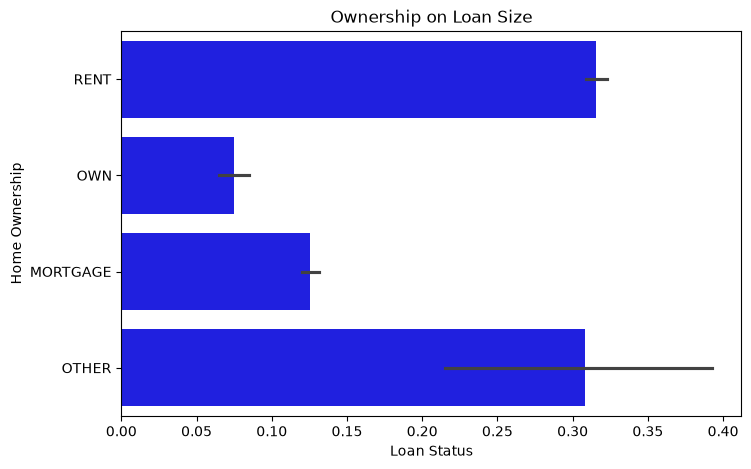

In [ ]:
plt.figure(figsize=(8,5))

sns.barplot(data=Credit, x='loan_status', y='person_home_ownership', color='blue')
plt.xlabel("Loan Status")
plt.ylabel("Home Ownership")
plt.title("Ownership on Loan Size")
plt.show()

In [15]:
Credit

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,loan_income_tier,age_group
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3,> 30%,Young Adult
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2,< 10%,Young Adult
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3,> 30%,Young Adult
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2,> 30%,Young Adult
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4,> 30%,Young Adult
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32576,57,53000,MORTGAGE,1.0,PERSONAL,C,5800,13.16,0,0.11,N,30,10% - 20%,Senior
32577,54,120000,MORTGAGE,4.0,PERSONAL,A,17625,7.49,0,0.15,N,19,10% - 20%,Middle-Aged
32578,65,76000,RENT,3.0,HOMEIMPROVEMENT,B,35000,10.99,1,0.46,N,28,> 30%,Senior
32579,56,150000,MORTGAGE,5.0,PERSONAL,B,15000,11.48,0,0.10,N,26,< 10%,Senior


In [16]:
Credit.to_csv('credit_dataset.csv', index=False)